**DESCRIPTIVE STATISTICS**

The dataset after extensive data wrangling and filtering is set for data analysis. We go from analysing the target or dependent variable i.e. 'No_show' and the independent variables such as 'Age', 'Gender', 'Hypertension', etc.
We will focus on the independent variables individually and then analyse the relationship between independent variables and dependent variable 

In [99]:
#Firstly, import modules necessary for analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

The First variable we'll be analysing is the target or dependent variable - 'No_Show' which has binary values and is a categorical outcome

In [100]:
#Import dataset
no_show_analysis = pd.read_csv('no_show_data_clean.csv')
no_show_analysis.head()

,Unnamed: 0,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
0,0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52
1,1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33
2,2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56
3,3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29
4,4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37


Before we continue any further,we will drop the first column - 'Unnamed: 0'

In [101]:
#Drop first column
no_show_analysis = no_show_analysis.drop(columns=['Unnamed: 0'])

In [102]:
no_show_analysis.head()

,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52
1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33
2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56
3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29
4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37


In [103]:
no_show_analysis.shape

(110516, 13)

In analysing the target variable, it is important determining the proportion of people who made their medical appointment to those who didn't show up. Since this is a categorical variable, mode(which is the most occurring value) is the measure of central tendency most suited. However, for clarity, we'll also make use of the value_counts function.

In [104]:
#Determining mode
#Caveat: numpy module has no attribute mode
no_show_analysis['No_Show'].mode()

0    No
Name: No_Show, dtype: object

In [105]:
#For clarity, let's use the value_counts function to see the proportion of No shows
no_show_analysis['No_Show'].value_counts(normalize = True) * 100

No_Show
No     79.811973
Yes    20.188027
Name: proportion, dtype: float64

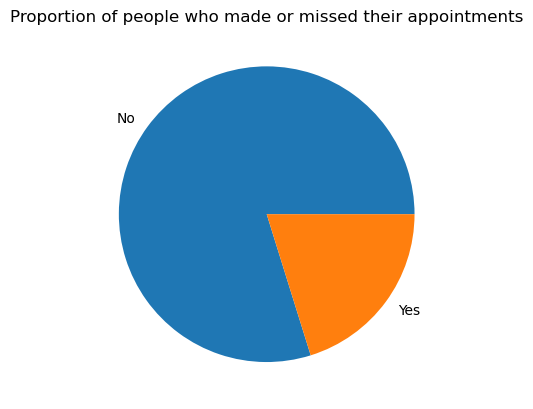

In [106]:
#Visualise above using pie chart
plt.pie(no_show_analysis['No_Show'].value_counts(), labels = no_show_analysis['No_Show'].value_counts().index)
plt.title('Proportion of people who made or missed their appointments')
plt.savefig('pie chart proportion.png')
plt.show()

From the above, ~80% of patients made it to their appointments while ~20% didn't. In simpler terms, 8 out of 10 patients did make it while 2 in 10 didn't. 

We'll be analysing other independent variables of interest.

Firstly, let's analyse the 'Gender' column.

This is a categorical binary variable.

In [107]:
#mode of 'Gender' column
no_show_analysis['Gender'].mode()

0    F
Name: Gender, dtype: object

In [108]:
#Number of values in 'Gender' column
no_show_analysis['Gender'].value_counts()

Gender
F    71831
M    38685
Name: count, dtype: int64

In [109]:
#Proportion of values in 'Gender' column
no_show_analysis['Gender'].value_counts(normalize = True) * 100

Gender
F    64.996019
M    35.003981
Name: proportion, dtype: float64

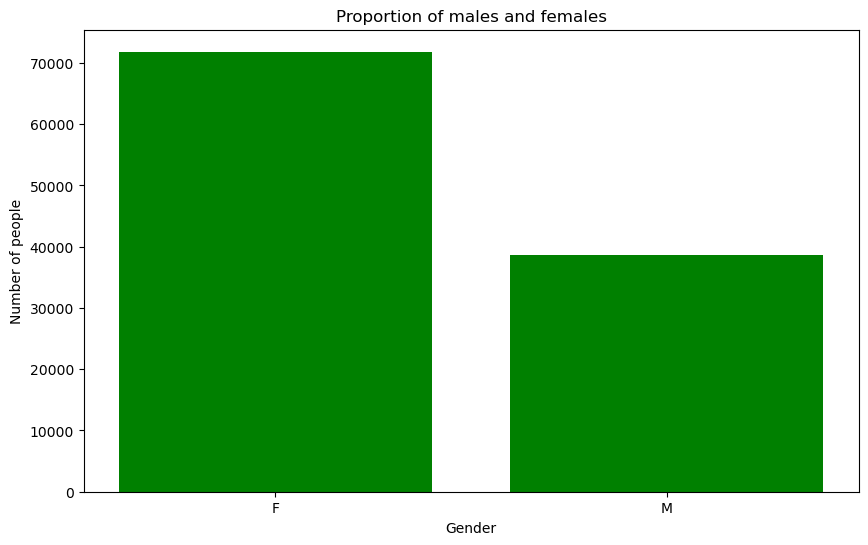

In [110]:
#Visualising the above using a bar chart
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis['Gender'].value_counts().index, no_show_analysis['Gender'].value_counts(), color = 'green')
plt.title('Proportion of males and females')
plt.xlabel('Gender')
plt.ylabel('Number of people')
plt.savefig('Proportion of males and females.png')
plt.show()

females make up 65% of dataset. while males the other 35%.
However, Determining the proportion of males to females based on who came and who didn't is more important than above analysis.
We'll be using the groupby function to determine proportion.
We'll also visualise the values in the variable

In [111]:
#Grouping 'Gender' based on outcome of 'No_Show'
no_show_analysis.groupby('Gender')['No_Show'].value_counts(normalize = True) * 100

Gender  No_Show
F       No         79.69122
        Yes        20.30878
M       No         80.03619
        Yes        19.96381
Name: proportion, dtype: float64

From the above, ~8 in 10 females made it to their appointment while ~2 in 10 didn't.
It is surprisingly the same for males.
Below, we'll visualise our data to see if females did make or miss their appointments more than males using a bar chart.

In [112]:
#Before visualisation of data, let's filter data based on outcome in the 'No_show' column
no_show_analysis_No = no_show_analysis[no_show_analysis['No_Show'] == 'No']
no_show_analysis_Yes = no_show_analysis[no_show_analysis['No_Show'] == 'Yes']

In [113]:
#Let's look at our new dataset
no_show_analysis_No.head()

,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52
1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33
2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56
3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29
4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37


In [114]:
no_show_analysis_Yes.head()

,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time
6,F,2016-04-27 15:05:12+00:00,2016-04-29 00:00:00+00:00,23,GOIABEIRAS,0,0,0,0,0,0,Yes,1 days 08:54:48
7,F,2016-04-27 15:39:58+00:00,2016-04-29 00:00:00+00:00,39,GOIABEIRAS,0,0,0,0,0,0,Yes,1 days 08:20:02
11,M,2016-04-26 08:44:12+00:00,2016-04-29 00:00:00+00:00,29,NOVA PALESTINA,0,0,0,0,0,1,Yes,2 days 15:15:48
17,F,2016-04-28 09:28:57+00:00,2016-04-29 00:00:00+00:00,40,CONQUISTA,1,0,0,0,0,0,Yes,0 days 14:31:03
20,F,2016-04-27 07:51:14+00:00,2016-04-29 00:00:00+00:00,30,NOVA PALESTINA,0,0,0,0,0,0,Yes,1 days 16:08:46


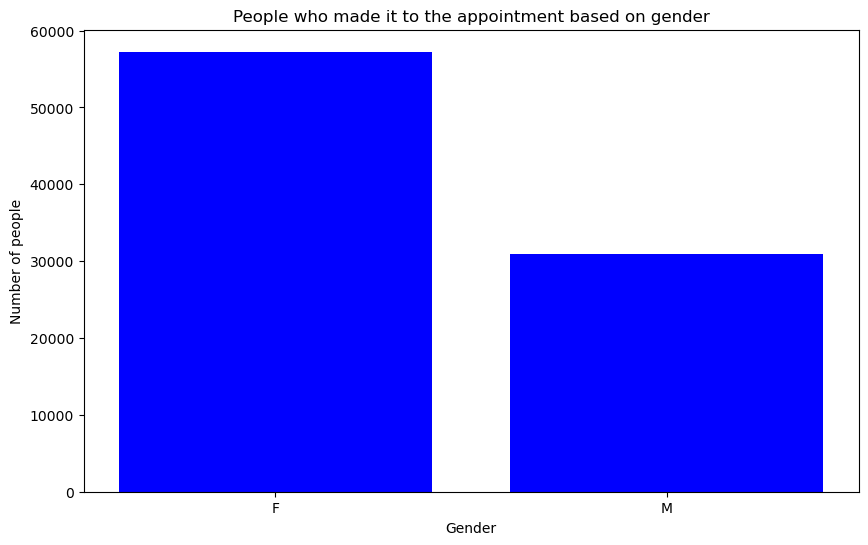

In [115]:
#Visualising these datasets using a bar chart
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_No['Gender'].value_counts().index, no_show_analysis_No['Gender'].value_counts(), color = 'blue')
plt.title('People who made it to the appointment based on gender')
plt.xlabel('Gender')
plt.ylabel('Number of people')
plt.savefig('People who made it to the appointment based on gender.png')
plt.show()

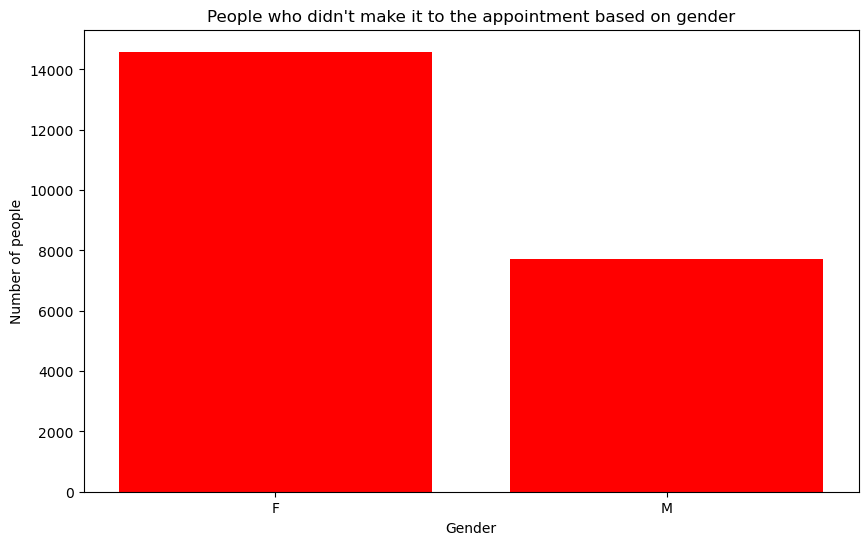

In [116]:
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_Yes['Gender'].value_counts().index, no_show_analysis_Yes['Gender'].value_counts(), color = 'red')
plt.title("People who didn't make it to the appointment based on gender")
plt.xlabel('Gender')
plt.ylabel('Number of people')
plt.savefig("People who didn't make it to the appointment based on gender.png")
plt.show()

From the above diagrams, more females made it to their appointments compared to males. Females also missed their appointments more than males.

We'll be analysing the 'Age' column next to see which age groups are more prone to make or miss their appointments.
We'll be making use of a histogram for clear visualisation.

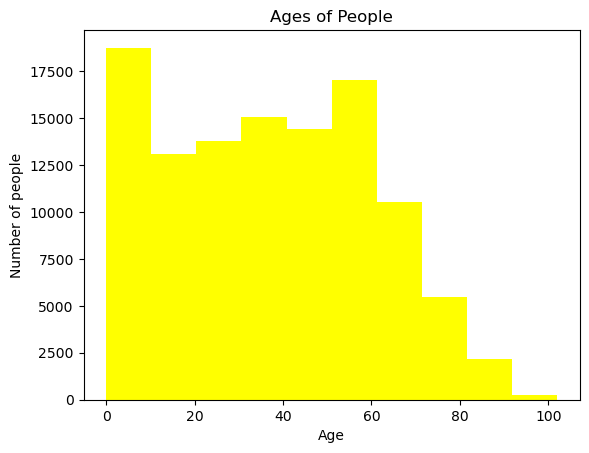

In [117]:
#Plotting a histogram for values in the 'Age' column in the entire dataset
plt.hist(no_show_analysis['Age'], bins = 10, color = 'yellow')
plt.title('Ages of People')
plt.xlabel('Age')
plt.ylabel('Number of people')
plt.savefig('Ages of People.png')
plt.show()

Largest population group lie between 0-10 years while the smallest group fall between 90-100.

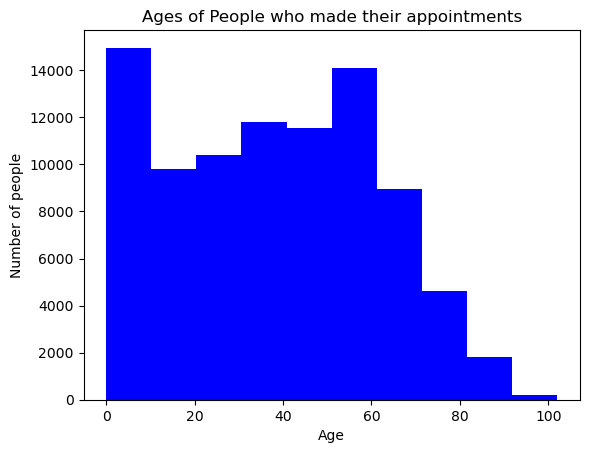

In [118]:
#Since we've filtered the dataset based on the outcome 'No_Show' earlier, we'll make use of those datasets for easy readability
plt.hist(no_show_analysis_No['Age'], bins = 10, color = 'blue')
plt.title('Ages of People who made their appointments')
plt.xlabel('Age')
plt.ylabel('Number of people')
plt.savefig('Ages of People who made their appointments.png')
plt.show()

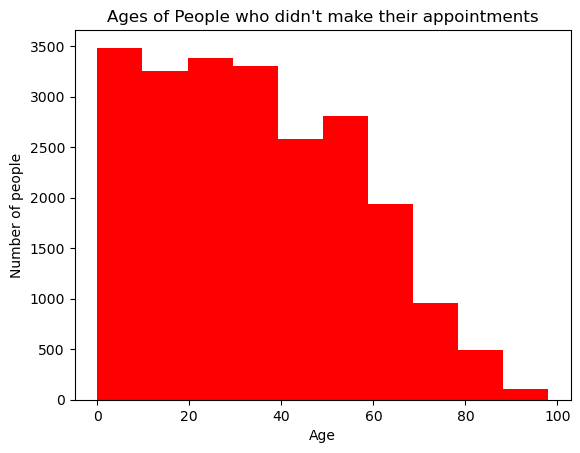

In [119]:
#Visualisation of Ages of People who didn't make their appointments
plt.hist(no_show_analysis_Yes['Age'], bins = 10, color = 'red')
plt.title("Ages of People who didn't make their appointments")
plt.xlabel('Age')
plt.ylabel('Number of people')
plt.savefig("Ages of People who didn't make their appointments.png")
plt.show()

Here, individuals between 0 - 10 years were the highest population group among those who missed their appointment. Closely followed by those between 20 - 30 years and then 30 - 40 years.
The lowest population group were those between 90 - 100 years.

We'll apply measures of central tendency to the 'Age' column. In this case, we will make use of the median because values in this column aren't normally distributed(previously represented during visualisation). This is generally expected in large samples of human population or even the human population themselves.

In [120]:
#Using numpy, let's determine the median of this dataset
np.median(no_show_analysis['Age'])

np.float64(37.0)

In [121]:
#Let's also determine the median age of people who made the appointment
np.median(no_show_analysis_No['Age'])

np.float64(38.0)

In [122]:
#median age of people who missed the appointment
np.median(no_show_analysis_Yes['Age'])

np.float64(33.0)

From the above, the median age in the whole dataset is 37 years.
The median age of people who made the appointment is 38 years.
The median age of people who missed the appointment is 33 years.

To determine measure of spread, Standard deviation is the generally used tool but instead, we'll be making use of the Median Absolute Deviation which is a more robust and outlier-resistant measure of variability. Also, keep in mind we did make use of the median as measure of central tendency earlier due to data in the variable being skewed.
Let's calculate the MAD below

In [123]:
# 1. Calculate the median of the overall dataset
np_data = np.array(no_show_analysis['Age'])
median_val = np.median(np_data)

In [124]:
median_val

np.float64(37.0)

In [125]:
# 2. Calculate the absolute deviations from the median
absolute_deviations = np.abs(np_data - median_val)
absolute_deviations

array([25., 19., 25., ..., 16.,  1., 17.])

In [126]:
# 3. Calculate the median of these absolute deviations
mad_value = np.median(absolute_deviations)
mad_value

np.float64(19.0)

The median absolute deviation for ages in the overall dataset is 19.0.
Let's also calculate the MAD for ages of people who made and missed their appointment.

In [127]:
#Calculating the median age of people who made their appointment
np_data_No = np.array(no_show_analysis_No['Age'])
median_val_No = np.median(np_data_No)

In [128]:
#Calculating deviations from the median
absolute_deviations_No = np.abs(np_data_No - median_val_No)
absolute_deviations_No

array([24., 18., 24., ..., 17.,  0., 16.])

In [129]:
#Calculating the median of these absolute deviations
mad_value_No = np.median(absolute_deviations_No)
mad_value_No

np.float64(19.0)

Here, the median absolute deviation is also 19.0.
Let's find out the MAD for those who missed their appointment

In [130]:
#Calculating the median age of people who missed their appointment
np_data_Yes = np.array(no_show_analysis_Yes['Age'])
median_val_Yes = np.median(np_data_Yes)

In [131]:
#Calculating deviations from the median
absolute_deviations_Yes = np.abs(np_data_Yes - median_val_Yes)
absolute_deviations_Yes

array([10.,  6.,  4., ...,  4.,  0.,  4.])

In [132]:
#Calculating the median of these absolute deviations
mad_value_Yes = np.median(absolute_deviations_Yes)
mad_value_Yes

np.float64(17.0)

The median absolute deviation among ages of people who missed appointment is also 17.0.

Another measure of spread which can be used is the interquartile range(IQR). This is prefered for skewed distribution like that in the variable of interest - 'Age'.
It tells us the spread of the middle 50% of our data, indicating how clustered or spread out the central values are

In [133]:
#Firstly, let's determine our first quartile/25th percentile
Q1 = np.percentile(no_show_analysis['Age'], 25)

In [134]:
#Then our third quartile or 75th percentile'
Q3 = np.percentile(no_show_analysis['Age'], 75)

In [135]:
#Our IQR = Q3 - Q1
IQR = Q3 - Q1
IQR

np.float64(37.0)

Our interquartile range is 37.0 which is same as the median of the dataset.

In [136]:
#IQR of ages of persons who made appointment
#Lets determine our first quartile/25th percentile and third quartile or 75th percentile
Q1_No = np.percentile(no_show_analysis_No['Age'], 25)
Q3_No = np.percentile(no_show_analysis_No['Age'], 75)

In [137]:
#IQR of ages of people who made appointmentt
IQR_No = Q3_No - Q1_No
IQR_No

np.float64(38.0)

In [138]:
#IQR of ages of persons who missed appointment
#Lets determine our first quartile/25th percentile and third quartile or 75th percentile
Q1_Yes = np.percentile(no_show_analysis_Yes['Age'], 25)
Q3_Yes = np.percentile(no_show_analysis_Yes['Age'], 75)

In [139]:
#IQR of ages of people who missed appointmentt
IQR_Yes = Q3_Yes - Q1_Yes
IQR_Yes

np.float64(35.0)

IQR for age among people who made appointment is 38.0 while among those who missed appointment is 35.0

The next step in analysing 'Scholarship' column. This is Bolsa Família, a social welfare program in Brazil.
This is a binary categorical variable where values 0/1 can be depicted as No/Yes respectively
We will be determining individuals with scholarships and those without in the general population and among those that missed and those who made appointments.
We'll be making use of the mode and/or value counts function in this analysis

In [140]:
#Value Counts of values in 'Scholarship' column
no_show_analysis['Scholarship'].value_counts()

Scholarship
0    99655
1    10861
Name: count, dtype: int64

In [141]:
#Proportion of people with enrolled in a Scholarship
no_show_analysis['Scholarship'].value_counts(normalize = True) * 100

Scholarship
0    90.172464
1     9.827536
Name: proportion, dtype: float64

The most occurring value(mode) in the 'Scholarship' column is 0 which means 'No'. 90% of individuals in this dataset aren't enrolled in the social welfare program'.

Let's further evaluate number and proportion of individuals with scholarships that made and missed their appointments.

In [142]:
#Value Counts of values in 'Scholarship' column among people who made the appointment
no_show_analysis_No['Scholarship'].value_counts()

Scholarship
0    79922
1     8283
Name: count, dtype: int64

In [143]:
#Proportion of people above
no_show_analysis_No['Scholarship'].value_counts(normalize = True) * 100

Scholarship
0    90.609376
1     9.390624
Name: proportion, dtype: float64

In [144]:
#Value Counts of values in 'Scholarship' column among people who missed the appointment
no_show_analysis_Yes['Scholarship'].value_counts()

Scholarship
0    19733
1     2578
Name: count, dtype: int64

In [145]:
#Proportion of people above
no_show_analysis_Yes['Scholarship'].value_counts(normalize = True) * 100

Scholarship
0    88.445162
1    11.554838
Name: proportion, dtype: float64

Let's visualise proportion of people with scholarships who made or missed their appointments

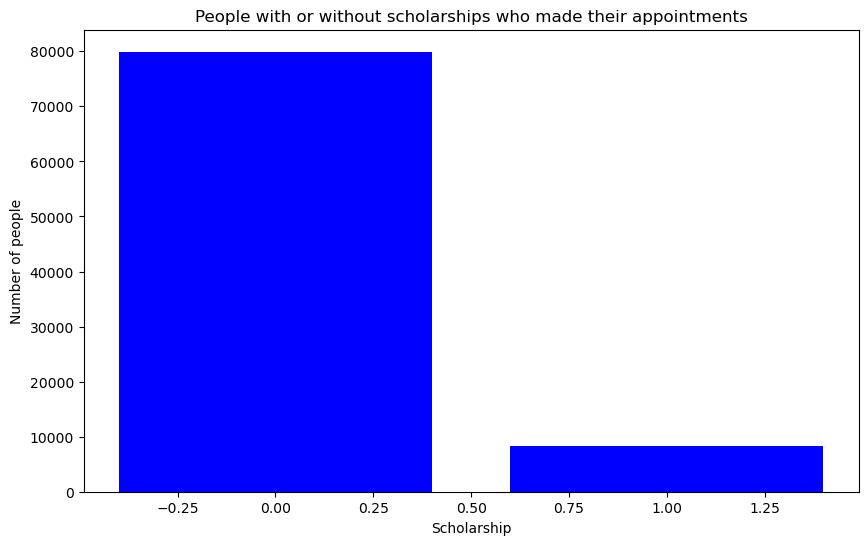

In [146]:
#Visualising values in 'Scholarship' Column among individuals that made their appointments
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_No['Scholarship'].value_counts().index, no_show_analysis_No['Scholarship'].value_counts(), color = 'blue' )
plt.title('People with or without scholarships who made their appointments')
plt.xlabel('Scholarship')
plt.ylabel('Number of people')
plt.savefig('People with or without scholarships who made their appointments.png')
plt.show()

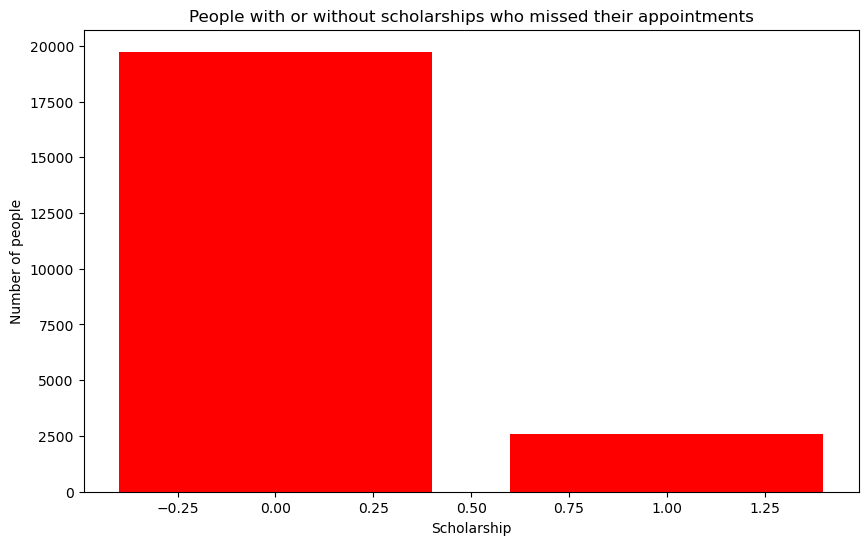

In [147]:
#Visualising values in 'Scholarship' Column among individuals that missed their appointments
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_Yes['Scholarship'].value_counts().index, no_show_analysis_Yes['Scholarship'].value_counts(), color = 'red')
plt.title('People with or without scholarships who missed their appointments')
plt.xlabel('Scholarship')
plt.ylabel('Number of people')
plt.savefig('People with or without scholarships who missed their appointments.png')
plt.show()

Among people who made appointments, ~91 in every 100 of them weren't enrolled in the social welfare program.
While among those who missed appointments, ~88 in every 100 weren't enrolled.

Next, we'll be analysing the 'Hypertension' column.
To describe individuals with hypertension in overall dataset and also relationship between hypertension and 'No shows'.
Just like the 'Scholarship' variable, this is a binary categorical variable with values 0/1 can be depicted as No/Yes respectively
Let's see the number of individuals with and without hypertension

In [148]:
#Number of individuals with or without hypertension in the 'Hypertension' column
no_show_analysis['Hypertension'].value_counts()

Hypertension
0    88716
1    21800
Name: count, dtype: int64

In [149]:
#Proportion
no_show_analysis['Hypertension'].value_counts(normalize = True) * 100

Hypertension
0    80.274349
1    19.725651
Name: proportion, dtype: float64

From the above, 80% of the sample do not have hypertension.

Let's further see individuals with or without hypertension among people who missed and made their appointments using the groupby function.

In [150]:
#Using the groupby function to categorise hypertensives and non-hypertensives among people who made or missed their appointments
no_show_analysis.groupby('No_Show')['Hypertension'].value_counts()

No_Show  Hypertension
No       0               70177
         1               18028
Yes      0               18539
         1                3772
Name: count, dtype: int64

In [151]:
#Proportion of the above
no_show_analysis.groupby('No_Show')['Hypertension'].value_counts(normalize = True) * 100

No_Show  Hypertension
No       0               79.561249
         1               20.438751
Yes      0               83.093541
         1               16.906459
Name: proportion, dtype: float64

<function matplotlib.pyplot.show(close=None, block=None)>

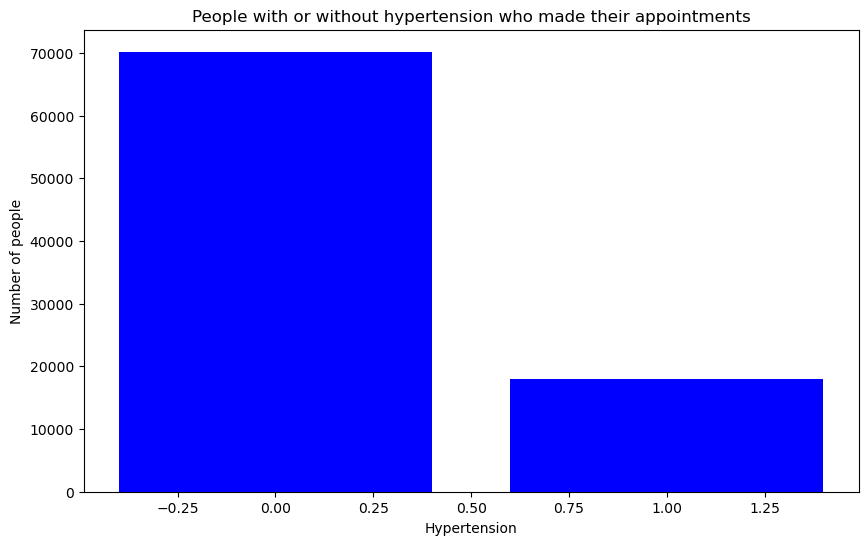

In [152]:
#Visualisation of hypertensives and non-hypertensives among people who made their appointment using a bar chart
#Remember, we have already filtered sample for that
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_No['Hypertension'].value_counts().index, no_show_analysis_No['Hypertension'].value_counts(), color = 'blue')
plt.title('People with or without hypertension who made their appointments')
plt.xlabel('Hypertension')
plt.ylabel('Number of people')
plt.savefig('People with or without hypertension who made their appointments.png')
plt.show

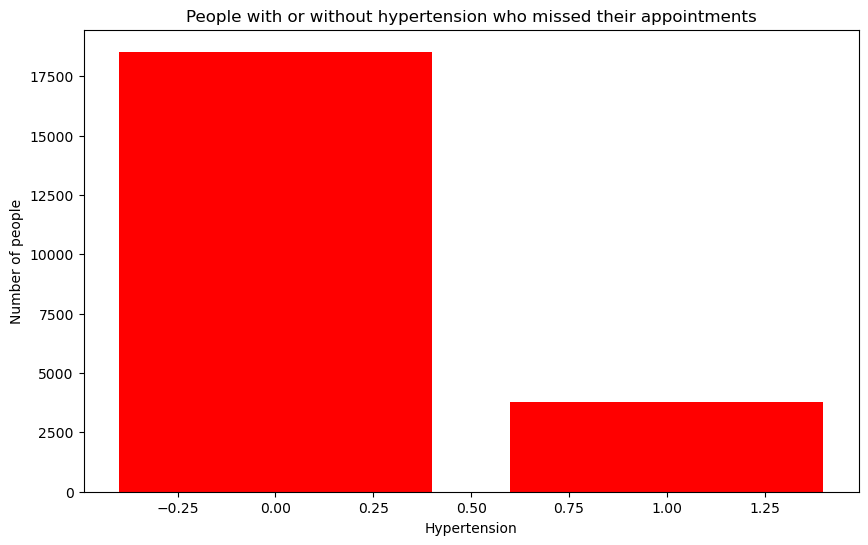

In [153]:
#Visualisation of hypertensives and non-hypertensives among people who missed their appointment using a bar chart
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_Yes['Hypertension'].value_counts().index, no_show_analysis_Yes['Hypertension'].value_counts(), color = 'red')
plt.title('People with or without hypertension who missed their appointments')
plt.xlabel('Hypertension')
plt.ylabel('Number of people')
plt.savefig('People with or without hypertension who missed their appointments.png')
plt.show()

From the above, ~80% of individuals who made their appointment weren't hypertensive while ~20% weren't.
~83% of individuals who were 'No shows' weren't hypertensive while ~17% were hypertensive.


Next variable we'll be analysing is the 'Diabetes' column.

This is a categorical variable as well with outcomes of 0/1 meaning No/Yes respectively.

We'll look at the number of individuals with and without diabetes.

In [154]:
#Number of individuals with diabetes in dataset
no_show_analysis['Diabetes'].value_counts()

Diabetes
0    102573
1      7943
Name: count, dtype: int64

In [155]:
#Proportion of the above
no_show_analysis['Diabetes'].value_counts(normalize = True) * 100

Diabetes
0    92.812805
1     7.187195
Name: proportion, dtype: float64

Here, ~93% of individuals do not have diabetes. 7% do have.

Let's compare individuals with or without diabetes in groups that made or missed appointments. 

In [156]:
#Using the groupby method to categoriize people who do or don't have diabetes among those who made and missed appointment
no_show_analysis.groupby('No_Show')['Diabetes'].value_counts()

No_Show  Diabetes
No       0           81692
         1            6513
Yes      0           20881
         1            1430
Name: count, dtype: int64

In [157]:
#Proportion of the above
no_show_analysis.groupby('No_Show')['Diabetes'].value_counts(normalize = True) * 100

No_Show  Diabetes
No       0           92.616065
         1            7.383935
Yes      0           93.590606
         1            6.409394
Name: proportion, dtype: float64

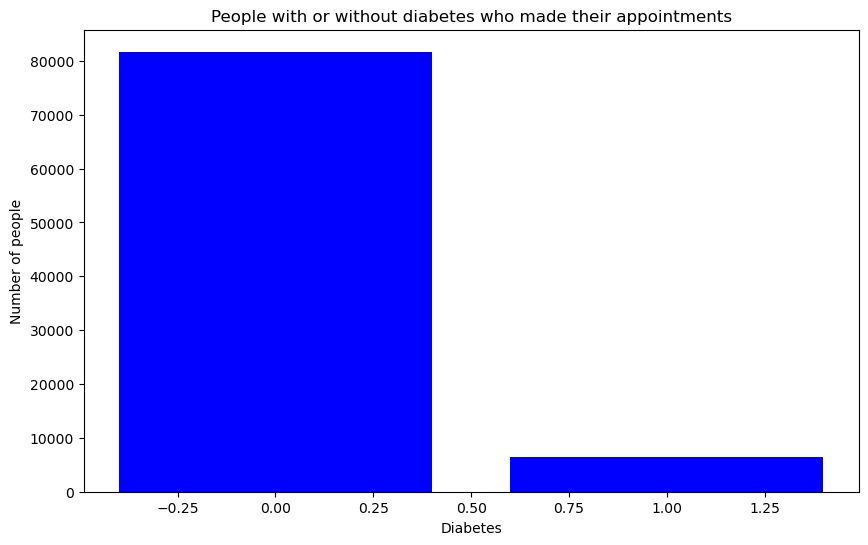

In [158]:
#Let's visualise using bar chart
#Remember, we do have a filtered dataset of individuals who made and missed appointment
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_No['Diabetes'].value_counts().index, no_show_analysis_No['Diabetes'].value_counts(), color = 'blue')
plt.title('People with or without diabetes who made their appointments')
plt.xlabel('Diabetes')
plt.ylabel('Number of people')
plt.savefig('People with or without diabetes who made their appointments.png')
plt.show()

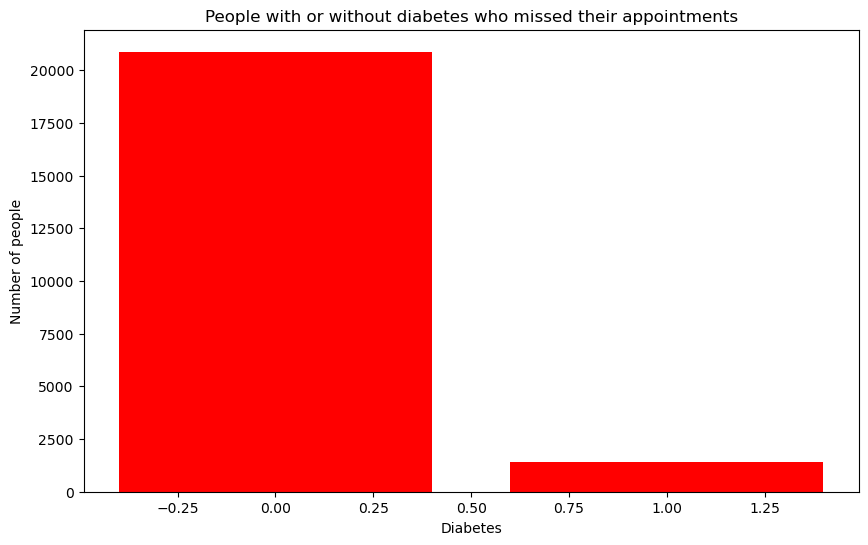

In [159]:
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_Yes['Diabetes'].value_counts().index, no_show_analysis_Yes['Diabetes'].value_counts(), color = 'red')
plt.title('People with or without diabetes who missed their appointments')
plt.xlabel('Diabetes')
plt.ylabel('Number of people')
plt.savefig('People with or without diabetes who missed their appointments.png')
plt.show()

From the analysis above, ~93% of people who made their appointments didn't have diabetes while the other 7% did.
94% of people who missed their appointments didn't have diabetes while 6% of them had.

We'll be analysing the 'Alcoholism' Feature next. This is a binary categorical variable with values similar to that of the 'Hypertension' and 'Diabetes' column.
Let's identify individuals who are alcoholics

In [160]:
#Alcoholics in dataset
no_show_analysis['Alcoholism'].value_counts()

Alcoholism
0    107156
1      3360
Name: count, dtype: int64

In [161]:
#Proportion
no_show_analysis['Alcoholism'].value_counts(normalize= True) * 100

Alcoholism
0    96.959716
1     3.040284
Name: proportion, dtype: float64

From the above, a mere 3% of sample are alcoholics. The rest are not.

Let's see alcoholics among people who made or miss appointments

In [162]:
#Number of people with or without alcoholism among those who made and missed appointments
no_show_analysis.groupby('No_Show')['Alcoholism'].value_counts()

No_Show  Alcoholism
No       0             85522
         1              2683
Yes      0             21634
         1               677
Name: count, dtype: int64

In [163]:
#Let's see the proportion of the above
no_show_analysis.groupby('No_Show')['Alcoholism'].value_counts(normalize=True) * 100

No_Show  Alcoholism
No       0             96.958222
         1              3.041778
Yes      0             96.965622
         1              3.034378
Name: proportion, dtype: float64

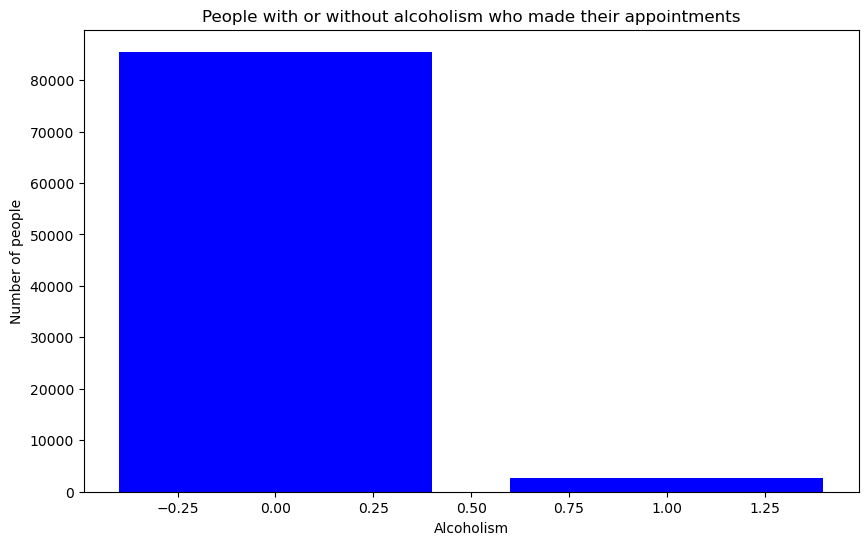

In [164]:
#Visualise the values among those who made or missed appointments using a bar chart
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_No['Alcoholism'].value_counts().index, no_show_analysis_No['Alcoholism'].value_counts(), color = 'blue')
plt.title('People with or without alcoholism who made their appointments')
plt.xlabel('Alcoholism')
plt.ylabel('Number of people')
plt.savefig('People with or without alcoholism who made their appointments.png')
plt.show()

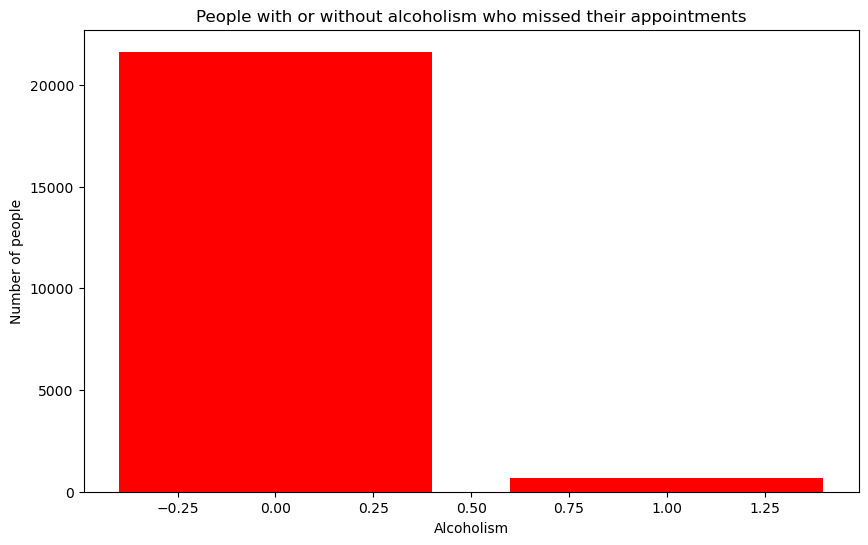

In [165]:
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_Yes['Alcoholism'].value_counts().index, no_show_analysis_Yes['Alcoholism'].value_counts(), color = 'red')
plt.title('People with or without alcoholism who missed their appointments')
plt.xlabel('Alcoholism')
plt.ylabel('Number of people')
plt.savefig('People with or without alcoholism who missed their appointments.png')
plt.show()

~97% of individuals who made appointments weren't alcoholics. Only 3% were.
This is the exact proportion among people who missed appointments.

Next variable for analysis is the 'Handicap'. This is a categorical variable. However, unlike the last 3 variables, the values in the column aren't binary. Values are ordinal and based on severity of handicap with 0 being absence of handicap and 4 being most severe handicap.

*Key*:
* 0 - no handicap
* 1 - mild handicap
* 2 - moderate handicap
* 3 - severe handicap
* 4 - very severe handicap/moribund

Below is the number and proportion of individuals who fall in this category


In [166]:
#Let's see the number of people handicapped in the dataset
no_show_analysis['Handicap'].value_counts()

Handicap
0    108281
1      2036
2       183
3        13
4         3
Name: count, dtype: int64

In [167]:
#Proportion of finding above
no_show_analysis['Handicap'].value_counts(normalize = True) * 100

Handicap
0    97.977668
1     1.842267
2     0.165587
3     0.011763
4     0.002715
Name: proportion, dtype: float64

~98% of persons in the dataset are not handicapped. The remaining 2% are handicapped but to varying degrees(keep in mind the key described earlier). 90% of the 2% who are handicapped are mildly handicapped.

Below, let's see number and proportion of handicapped persons among groups that made and missed appointments

In [168]:
#Using the groupby function to see number of handicapped persons among groups that made and missed appointments
no_show_analysis.groupby('No_Show')['Handicap'].value_counts()

No_Show  Handicap
No       0           86372
         1            1675
         2             146
         3              10
         4               2
Yes      0           21909
         1             361
         2              37
         3               3
         4               1
Name: count, dtype: int64

In [169]:
#Proportion of above
no_show_analysis.groupby('No_Show')['Handicap'].value_counts(normalize = True) * 100

No_Show  Handicap
No       0           97.921887
         1            1.898985
         2            0.165523
         3            0.011337
         4            0.002267
Yes      0           98.198198
         1            1.618036
         2            0.165837
         3            0.013446
         4            0.004482
Name: proportion, dtype: float64

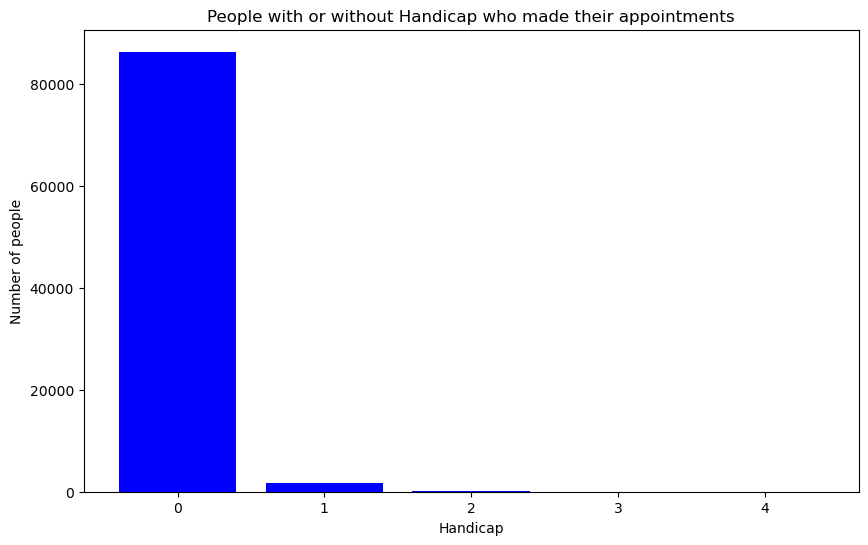

In [170]:
#Let's visualise findings
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_No['Handicap'].value_counts().index, no_show_analysis_No['Handicap'].value_counts(), color = 'blue')
plt.title('People with or without Handicap who made their appointments')
plt.xlabel('Handicap')
plt.ylabel('Number of people')
plt.savefig('People with or without Handicap who made their appointments.png')
plt.show()

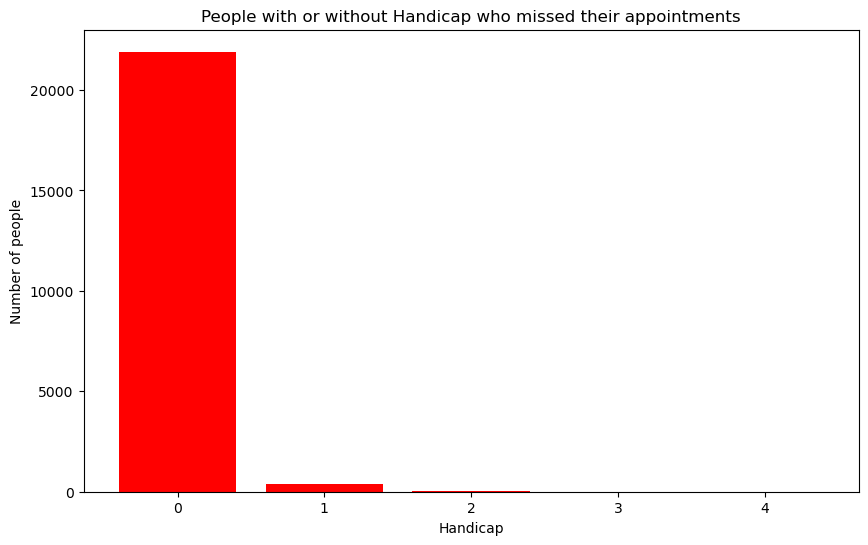

In [171]:
plt.figure(figsize = (10, 6))
plt.bar(no_show_analysis_Yes['Handicap'].value_counts().index, no_show_analysis_Yes['Handicap'].value_counts(), color = 'red')
plt.title('People with or without Handicap who missed their appointments')
plt.xlabel('Handicap')
plt.ylabel('Number of people')
plt.savefig('People with or without Handicap who missed their appointments.png')
plt.show()

From our findings above, ~98% of individuals who made their appointments weren't handicapped while the ~2% were handicapped to varying degrees.
This statistic is the same for individuals who missed their appointment.

Next variable to be analysed will be the 'SMS_Received' column. It is a categorical binary variable with values of 0/1 depicting No/Yes respectively.

Let's determine number of persons who got an SMS reminding them of their clinic visit

In [172]:
#Number of people who recieved SMS
no_show_analysis['SMS_Received'].value_counts()

SMS_Received
0    75035
1    35481
Name: count, dtype: int64

In [173]:
#Proportion of the above
no_show_analysis['SMS_Received'].value_counts(normalize = True) * 100

SMS_Received
0    67.895146
1    32.104854
Name: proportion, dtype: float64

~68% of persons didn't receive SMS while ~32% did receive.

Let's see the number and proportion of those who did or did not receive among people who made the appointment and 'No shows'

In [174]:
#Number of people who did or didn't receive SMS using the groupby function
no_show_analysis.groupby('No_Show')['SMS_Received'].value_counts()

No_Show  SMS_Received
No       0               62508
         1               25697
Yes      0               12527
         1                9784
Name: count, dtype: int64

In [175]:
#Proportion of above
no_show_analysis.groupby('No_Show')['SMS_Received'].value_counts(normalize = True) * 100

No_Show  SMS_Received
No       0               70.866731
         1               29.133269
Yes      0               56.147192
         1               43.852808
Name: proportion, dtype: float64

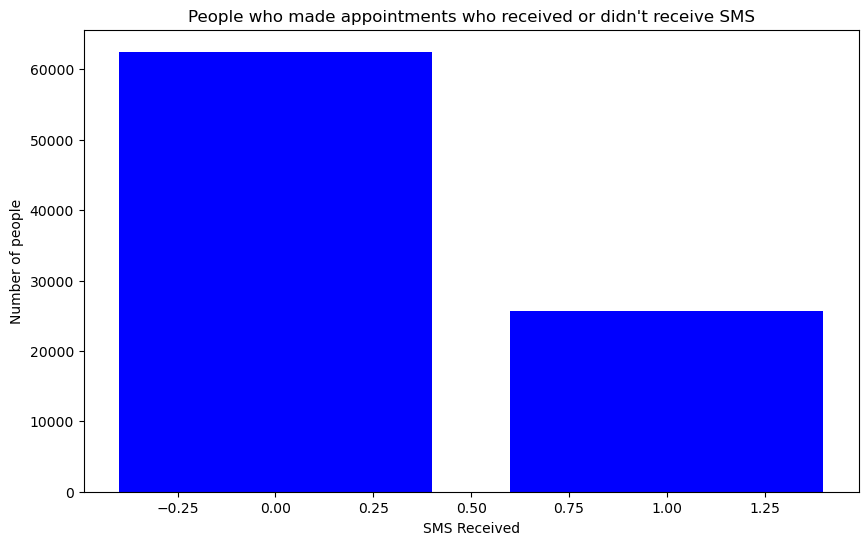

In [176]:
#Visualisation
plt.figure(figsize = (10,6))
plt.bar(no_show_analysis_No['SMS_Received'].value_counts().index, no_show_analysis_No['SMS_Received'].value_counts(), color = 'blue')
plt.title("People who made appointments who received or didn't receive SMS")
plt.xlabel('SMS Received')
plt.ylabel('Number of people')
plt.savefig("People who made appointments who received or didn't receive SMS.png")
plt.show()

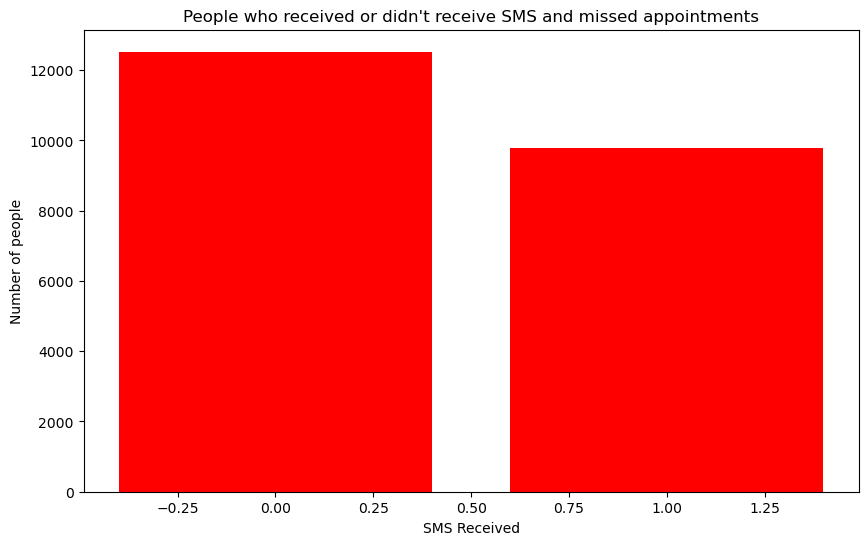

In [177]:
plt.figure(figsize = (10,6))
plt.bar(no_show_analysis_Yes['SMS_Received'].value_counts().index, no_show_analysis_Yes['SMS_Received'].value_counts(), color = 'red')
plt.title("People who received or didn't receive SMS and missed appointments")
plt.xlabel('SMS Received')
plt.ylabel('Number of people')
plt.savefig("People who received or didn't receive SMS and missed appointments.png")
plt.show()

Among those who made appointment, ~71% of them didn't receive SMS while ~29% of them did receive.
Among those who missed appointment, ~56% of them didn't receive SMS while ~44% of them did.

We will be analysing the 'Lead_Time' feature next. This is a categorical nominal variable with multiple values.
We would like to see shorter or longer lead time did affect outcome('No Show').
For our analysis, we'll be making use of;

* short lead time : <= 7 days
* long lead time : > 7 days

In [178]:
#We'll filter our dataset using above criteria
short_lead_time = no_show_analysis[no_show_analysis['Lead_Time'] <= '7 days']
long_lead_time = no_show_analysis[no_show_analysis['Lead_Time'] > '7 days']

In [179]:
#Let's see the number of persons who had a short lead time
short_lead_time.shape[0]

104443

In [180]:
#Let's see the number of persons who had a long lead time
long_lead_time.shape[0]

6073

In [181]:
#Proportion of people with short lead time
short_lead_time.shape[0] * 100/(short_lead_time.shape[0] + long_lead_time.shape[0])

94.50486807340114

In [182]:
#Proportion of people with short lead time
long_lead_time.shape[0] * 100/(short_lead_time.shape[0] + long_lead_time.shape[0])

5.495131926598863

From the above, ~95% of individuals had a short lead time. 5% had a long lead time.

Now , let's see the number and proportion of persons with short and long lead times among those who made and missed appointments

In [183]:
#Creating a new pipeline by filtering data
short_lead_time_made = short_lead_time[short_lead_time['No_Show'] == 'No']
short_lead_time_missed = short_lead_time[short_lead_time['No_Show'] == 'Yes']
long_lead_time_made = long_lead_time[long_lead_time['No_Show'] == 'No']
long_lead_time_missed = long_lead_time[long_lead_time['No_Show'] == 'Yes']

In [184]:
#Number of persons in new pipelines
short_lead_time_made.shape[0]

83897

In [185]:
short_lead_time_missed.shape[0]

20546

In [186]:
long_lead_time_made.shape[0]

4308

In [187]:
long_lead_time_missed.shape[0]

1765

In [188]:
#Calculating proportions
short_lead_time_made.shape[0] * 100/(short_lead_time_made.shape[0] + long_lead_time_made.shape[0])

95.1159231336092

In [189]:
long_lead_time_made.shape[0] * 100/(short_lead_time_made.shape[0] + long_lead_time_made.shape[0])

4.884076866390794

In [190]:
short_lead_time_missed.shape[0] * 100/(short_lead_time_missed.shape[0] + long_lead_time_missed.shape[0])

92.08910402940253

In [191]:
long_lead_time_missed.shape[0] * 100/(short_lead_time_missed.shape[0] + long_lead_time_missed.shape[0])

7.910895970597463

From the above, ~95% of persons that made appointment had a short lead time while ~5% that made appointment had a long lead time.
~92% who missed appointment had a short lead time and the remaining ~8% had a long time.

We will do some bit of feature engineering to determine days of the week and month of the year.
The goal is to know which days people mostly make or miss appointments.

In [192]:
#Creating new pipeline
no_show_analysis1 = no_show_analysis.copy()

In [193]:
#Confirming data type of columns
no_show_analysis1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110516 entries, 0 to 110515
Data columns (total 13 columns):
 #   Column           Non-Null Count   Dtype 
---  ------           --------------   ----- 
 0   Gender           110516 non-null  object
 1   Scheduled_Day    110516 non-null  object
 2   Appointment_Day  110516 non-null  object
 3   Age              110516 non-null  int64 
 4   Neighbourhood    110516 non-null  object
 5   Scholarship      110516 non-null  int64 
 6   Hypertension     110516 non-null  int64 
 7   Diabetes         110516 non-null  int64 
 8   Alcoholism       110516 non-null  int64 
 9   Handicap         110516 non-null  int64 
 10  SMS_Received     110516 non-null  int64 
 11  No_Show          110516 non-null  object
 12  Lead_Time        110516 non-null  object
dtypes: int64(7), object(6)
memory usage: 11.0+ MB


In [194]:
#Let's convert 'Scheduled_Day' and 'Appointment_Day' to datetime series
no_show_analysis1['Scheduled_Day'] = pd.to_datetime(no_show_analysis1['Scheduled_Day'])
no_show_analysis1['Appointment_Day'] = pd.to_datetime(no_show_analysis1['Appointment_Day'])

In [195]:
#Let's create a new column of day and month using 'Appointment_Day'
no_show_analysis1['Day'] = no_show_analysis1['Appointment_Day'].dt.day_name()
no_show_analysis1['Month'] = no_show_analysis1['Appointment_Day'].dt.month_name()

In [196]:
#Inspecting our data
no_show_analysis1.head()

,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time,Day,Month
0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52,Friday,April
1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33,Friday,April
2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56,Friday,April
3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29,Friday,April
4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37,Friday,April


In [197]:
#Let's filter data based on people who made and missed appointments with relation to the 'No_Show' column
no_show_analysis1_No = no_show_analysis1[no_show_analysis1['No_Show'] == 'No']
no_show_analysis1_Yes = no_show_analysis1[no_show_analysis1['No_Show'] == 'Yes']

Let's see what days and months do people make and miss appointments the most in new pipelines.

In [198]:
#Most occurring days among people who made appointments
no_show_analysis1_No['Day'].value_counts()

Day
Wednesday    20774
Tuesday      20488
Monday       18023
Friday       14981
Thursday     13909
Saturday        30
Name: count, dtype: int64

In [199]:
#Proportion of the above
no_show_analysis1_No['Day'].value_counts(normalize = True) * 100

Day
Wednesday    23.551953
Tuesday      23.227708
Monday       20.433082
Friday       16.984298
Thursday     15.768947
Saturday      0.034012
Name: proportion, dtype: float64

In [200]:
#Most occurring months among people who made appointments
no_show_analysis1_No['Month'].value_counts()

Month
May      64036
June     21567
April     2602
Name: count, dtype: int64

In [201]:
#Proportion of the above
no_show_analysis1_No['Month'].value_counts(normalize = True) * 100

Month
May      72.599059
June     24.450995
April     2.949946
Name: proportion, dtype: float64

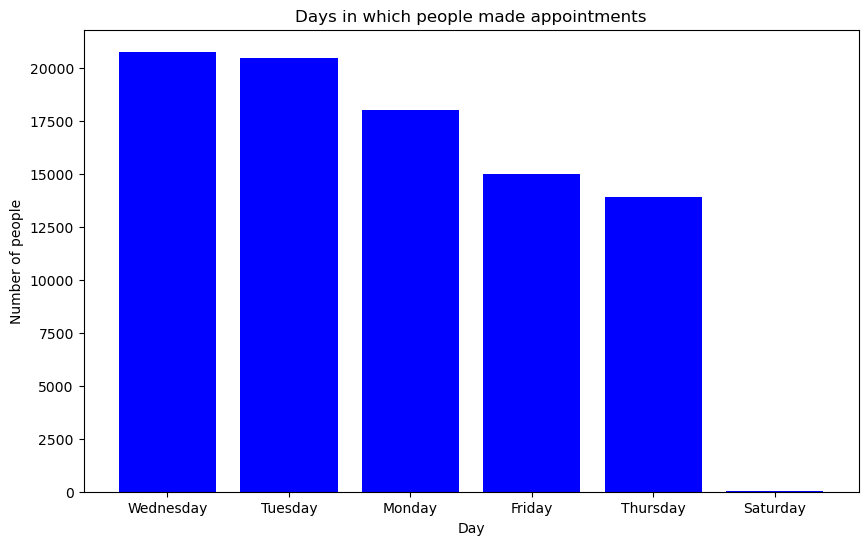

In [202]:
#Visualising days in which people made appointments
plt.figure(figsize=(10,6))
plt.bar(no_show_analysis1_No['Day'].value_counts().index, no_show_analysis1_No['Day'].value_counts(), color = 'blue')
plt.title('Days in which people made appointments')
plt.xlabel('Day')
plt.ylabel('Number of people')
plt.savefig('Days in which people made appointments.png')
plt.show()

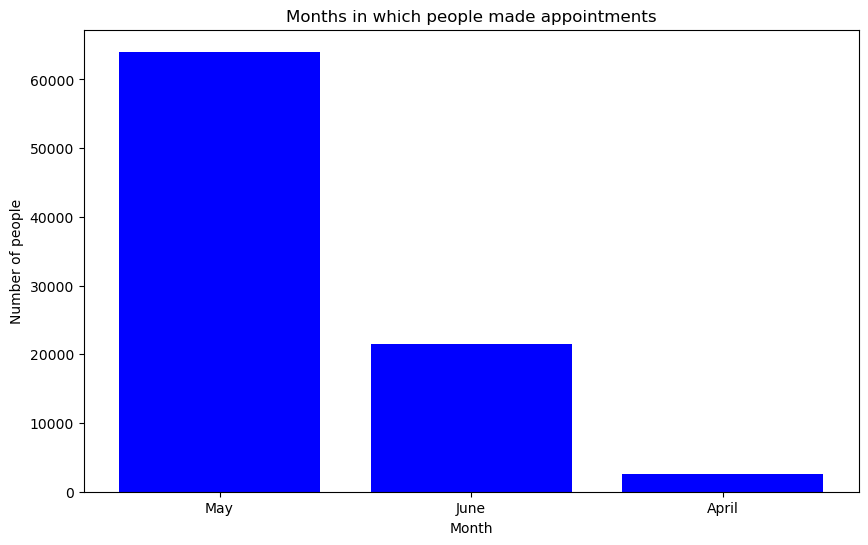

In [203]:
#Visualising months in which people made appointments
plt.figure(figsize=(10,6))
plt.bar(no_show_analysis1_No['Month'].value_counts().index, no_show_analysis1_No['Month'].value_counts(), color = 'blue')
plt.title('Months in which people made appointments')
plt.xlabel('Month')
plt.ylabel('Number of people')
plt.savefig('Months in which people made appointments.png')
plt.show()

From the analysis above with respect to people who made appointment ~24% of people who made appointments came on wednesday. 0.03% of these people came on saturday making it the least busiest day. In addition, data wasn't collected for sundays or clinics weren't functional that day.

In analysing the months, it's quite evident data collected was for clinic visits between April - May of 2016. ~73% of patients who made appointment came in the month of May while only ~3% of them came in April.


Let's do the same for individuals who missed appointments. What day was likely to be missed and what month had the highest 'No-shows'

In [204]:
#Most occurring days among people who missed appointments
no_show_analysis1_Yes['Day'].value_counts()

Day
Tuesday      5150
Wednesday    5092
Monday       4688
Friday       4037
Thursday     3335
Saturday        9
Name: count, dtype: int64

In [205]:
#Proportion of the above
no_show_analysis1_Yes['Day'].value_counts(normalize = True) * 100

Day
Tuesday      23.082784
Wednesday    22.822823
Monday       21.012057
Friday       18.094214
Thursday     14.947784
Saturday      0.040339
Name: proportion, dtype: float64

In [206]:
#Most occurring month among people who missed appointments
no_show_analysis1_Yes['Month'].value_counts()

Month
May      16796
June      4882
April      633
Name: count, dtype: int64

In [207]:
#Proportion
no_show_analysis1_Yes['Month'].value_counts(normalize = True) * 100

Month
May      75.281251
June     21.881583
April     2.837166
Name: proportion, dtype: float64

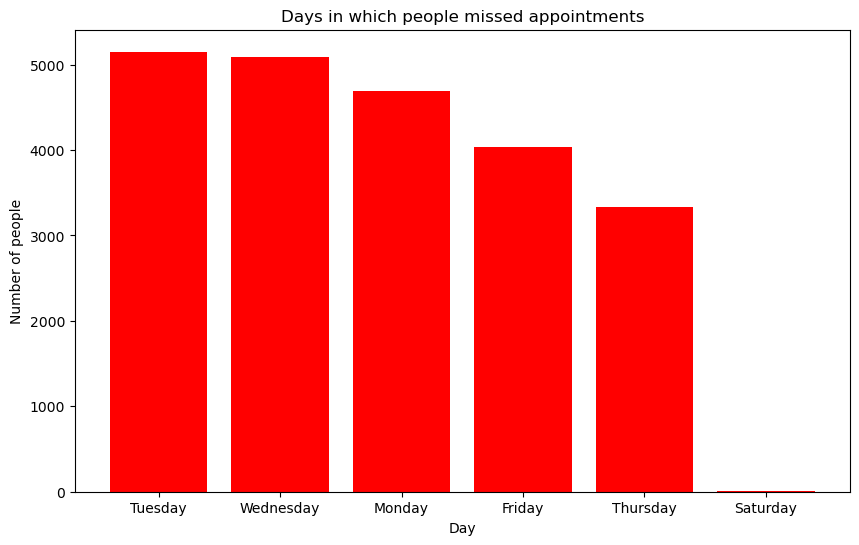

In [208]:
#Visualising days in which people missed appointments
plt.figure(figsize=(10,6))
plt.bar(no_show_analysis1_Yes['Day'].value_counts().index, no_show_analysis1_Yes['Day'].value_counts(), color = 'red')
plt.title('Days in which people missed appointments')
plt.xlabel('Day')
plt.ylabel('Number of people')
plt.savefig('Days in which people missed appointments.png')
plt.show()

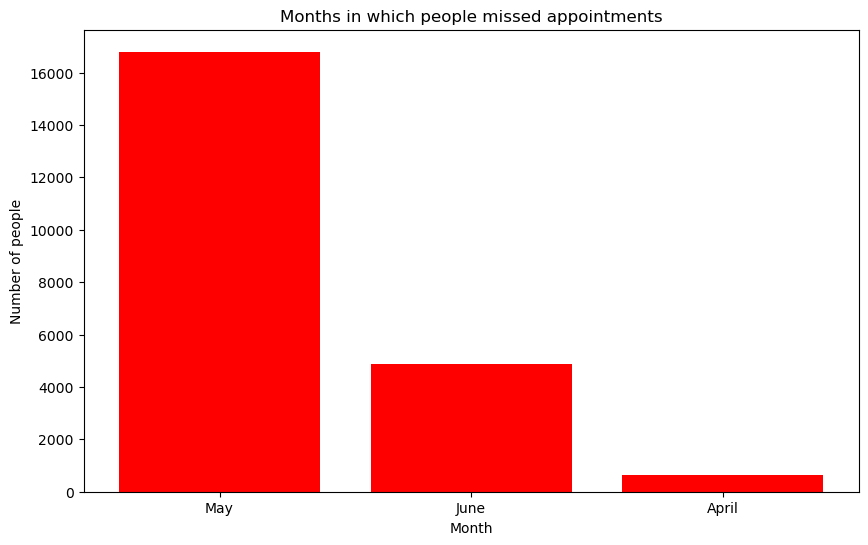

In [209]:
#Visualising months in which people missed appointments
plt.figure(figsize=(10,6))
plt.bar(no_show_analysis1_Yes['Month'].value_counts().index, no_show_analysis1_Yes['Month'].value_counts(), color = 'red')
plt.title('Months in which people missed appointments')
plt.xlabel('Month')
plt.ylabel('Number of people')
plt.savefig('Months in which people missed appointments.png')
plt.show()

23.1% of people booked for tuesday missed their appointments while 0.04% booked for saturday missed theirs as well.

~75% of people booked for clinic visits in May missed their appointment.

Finally, we'll see which neighbourhood had the highest cases of made and missed appointment. We'll be making use of the 'Neighbourhood' column which is a categorical norminal variable.

In [210]:
#Most occurring neighbourhoods in general sample
no_show_analysis1['Neighbourhood'].value_counts()

Neighbourhood
JARDIM CAMBURI                 7717
MARIA ORTIZ                    5805
RESISTÊNCIA                    4430
JARDIM DA PENHA                3877
ITARARÉ                        3514
                               ... 
ILHA DO BOI                      35
ILHA DO FRADE                    10
AEROPORTO                         8
ILHAS OCEÂNICAS DE TRINDADE       2
PARQUE INDUSTRIAL                 1
Name: count, Length: 81, dtype: int64

In [211]:
#Proportion of the above
no_show_analysis1['Neighbourhood'].value_counts(normalize = True) * 100

Neighbourhood
JARDIM CAMBURI                 6.982699
MARIA ORTIZ                    5.252633
RESISTÊNCIA                    4.008469
JARDIM DA PENHA                3.508089
ITARARÉ                        3.179630
                                 ...   
ILHA DO BOI                    0.031670
ILHA DO FRADE                  0.009048
AEROPORTO                      0.007239
ILHAS OCEÂNICAS DE TRINDADE    0.001810
PARQUE INDUSTRIAL              0.000905
Name: proportion, Length: 81, dtype: float64

There are 81 neighbourhoods where people in this dataset reside in.
7717 people(~7% of sample) live in Jardim Camburi while only 1 person lives in Parque Industrial

In [212]:
#Most occurring neighbourhoods among those who made appointment
no_show_analysis1_No['Neighbourhood'].value_counts()

Neighbourhood
JARDIM CAMBURI       6252
MARIA ORTIZ          4586
RESISTÊNCIA          3525
JARDIM DA PENHA      3246
SANTA MARTHA         2635
                     ... 
PONTAL DE CAMBURI      57
ILHA DO BOI            32
ILHA DO FRADE           8
AEROPORTO               7
PARQUE INDUSTRIAL       1
Name: count, Length: 80, dtype: int64

In [213]:
#Proportion of above
no_show_analysis1_No['Neighbourhood'].value_counts(normalize = True) * 100

Neighbourhood
JARDIM CAMBURI       7.088034
MARIA ORTIZ          5.199252
RESISTÊNCIA          3.996372
JARDIM DA PENHA      3.680063
SANTA MARTHA         2.987359
                       ...   
PONTAL DE CAMBURI    0.064622
ILHA DO BOI          0.036279
ILHA DO FRADE        0.009070
AEROPORTO            0.007936
PARQUE INDUSTRIAL    0.001134
Name: proportion, Length: 80, dtype: float64

In [214]:
#Most occurring neighbourhoods among those who missed appointment
no_show_analysis1_Yes['Neighbourhood'].value_counts()

Neighbourhood
JARDIM CAMBURI                 1465
MARIA ORTIZ                    1219
ITARARÉ                         923
RESISTÊNCIA                     905
CENTRO                          703
                               ... 
PONTAL DE CAMBURI                12
ILHA DO BOI                       3
ILHAS OCEÂNICAS DE TRINDADE       2
ILHA DO FRADE                     2
AEROPORTO                         1
Name: count, Length: 80, dtype: int64

In [215]:
#Proportion of the above
no_show_analysis1_Yes['Neighbourhood'].value_counts(normalize = True) * 100

Neighbourhood
JARDIM CAMBURI                 6.566268
MARIA ORTIZ                    5.463673
ITARARÉ                        4.136973
RESISTÊNCIA                    4.056295
CENTRO                         3.150912
                                 ...   
PONTAL DE CAMBURI              0.053785
ILHA DO BOI                    0.013446
ILHAS OCEÂNICAS DE TRINDADE    0.008964
ILHA DO FRADE                  0.008964
AEROPORTO                      0.004482
Name: proportion, Length: 80, dtype: float64

~7% of sample that made appointments reside in Jardim Camburi.
~7% of sample that missed appointments also reside in Jardim Camburi.


We've completed our descriptive analysis of the variables.
Next thing we'll be doing is if these findings can be generalised to the entire population using inferential statistics.
Keep in mind, our dataset is only a subset of the entire population.

**INFERENTIAL STATISTICS**

We'll be making use of tests of statistical significance such as t-tests, ANOVA, chi - square, etc; and confidence.
The aim is to determine if our findings in the descriptive analysis are significant enough to be generalised to the entire population.

Below is a list of what we intend using the inferential statistic for:

*	To determine relationship between age and ‘No show’.
*	To determine relationship between gender and ‘No show’.
*	To determine relationship between co-morbidities(hypertension, diabetes, alcoholism) and ‘No show’.
*	To determine effect of handicap on ‘No show’
*	To determine effect of SMS messages on outcome - ‘No show’.
*	To determine effect of Scholarship (This refers to Bolsa Família, a social welfare program in Brazil) on ‘No show’.
*	To determine relationship between lead time and ‘No-show’
*	To determine if Day or Month of Appointment have any effect on ‘No show’.
*	To make use of analytical insight to control or solve occurrences of ‘No show’.

We'll be making use of the scipy.stats module imported earlier

Let's determine relationship between gender and 'No-show'. We'll be using the chi-square test of independence to determine significance of this relationship

Let's establish our null(H0) and alternate(Ha) hypotheses before we begin:

H0: There is no relationship between gender and 'No show'

Ha: There is no relationship between gender and 'No show'

significance level = 0.05

In [216]:
 #Creating a new pipeline
no_show_analysis2 = no_show_analysis1.copy()

In [217]:
#From the scipy module, we'll be able to run our statistical test
from scipy import stats
from scipy.stats import chi2_contingency

In [218]:
#Create a contingency table
contingency_table1 = pd.crosstab(no_show_analysis2['Gender'], no_show_analysis2['No_Show'])
display(contingency_table1)

No_Show,No,Yes
Gender,,
F,57243,14588
M,30962,7723


In [219]:
#Running the chi2 test of independence
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table1)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table1.index, columns=contingency_table1.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between Gender and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between Gender and No_Show.")

Chi-square statistic: 1.8357300724579622
P-value: 0.1754522345307508
Degrees of freedom: 1


No_Show,No,Yes
Gender,,
F,57329.738273,14501.261727
M,30875.261727,7809.738273



Fail to reject the null hypothesis: There is no significant relationship between Gender and No_Show.


From the above, our p value of 0.175 which is higher than the alpha level of 0.05. In this situation, we fail to reject the null hypothesis. This in turn means *There is no significant relationship between Gender and No_Show.*

This relationship cannot be extrapolated to the general population.

Next we'll be focusing on the relationship between 'Age' and 'No_show'.
We'll be making use of the Mann Whitney U test to compare groups who made and missed appointment. We'll be using this statistic instead of the t-test because of the skewed nature of our distribution in the 'Age' column.

*Hypotheses*:

H0: There is no significant relationship between age and 'No show'

Ha: There is no significant relationship between age and 'No show'

alpha = 0.05

In [220]:
#Keep in mind we do have a previous pipeline for individual who made and missed their appointments
#We'll be grouping them against age
#This will give rise to 2 groups which will be used for our statistical testing
age_no_show_No = no_show_analysis1_No['Age']
age_no_show_Yes = no_show_analysis1_Yes['Age']

print(f"Shape of age_no_show_No: {age_no_show_No.shape[0]}")
print(f"Shape of age_no_show_Yes: {age_no_show_Yes.shape[0]}")

Shape of age_no_show_No: 88205
Shape of age_no_show_Yes: 22311


From the above, age_no_show_No is a series of ages of people who made their appointment
age_no_show_Yes is a series of ages of people who missed their appointment.

In [221]:
#Importing mannwhitneyu function from scipy.stats
from scipy.stats import mannwhitneyu

In [222]:
# Performing the Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(age_no_show_No, age_no_show_Yes, alternative='two-sided')

# Print the results
print(f"Mann-Whitney U statistic: {u_statistic}")
print(f"P-value: {p_value}")

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant difference in age distribution between patients who showed up and those who did not.")
else:
    print("\nFail to reject the null hypothesis: There is no significant difference in age distribution between patients who showed up and those who did not.")

Mann-Whitney U statistic: 1070733961.0
P-value: 2.4177757624095565e-92

Reject the null hypothesis: There is a significant difference in age distribution between patients who showed up and those who did not.


From our analysis above, the p value of 2.4177757624095565e-92 is infinitesimally smaller than the alpha level of 0.05.
This means we're rejecting the null hypothesis.

Therefore, *There is a significant difference in age distribution between patients who showed up and those who did not.*

We'll be determining the relationship between 'Scholarship' and 'No_Show'.
Does social welfare have an effect on making or missing appointments?
We'll make use of chi square of independence since these are both categorical variables.

In [224]:
#Creating a contingency table
contingency_table_scholarship = pd.crosstab(no_show_analysis2['Scholarship'], no_show_analysis2['No_Show'])
display(contingency_table_scholarship)

No_Show,No,Yes
Scholarship,,
0,79922,19733
1,8283,2578


In [225]:
#Using the chi2 test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table_scholarship)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table_scholarship.index, columns=contingency_table_scholarship.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between Scholarship and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between Scholarship and No_Show.")

Chi-square statistic: 93.87314247008572
P-value: 3.364079748857393e-22
Degrees of freedom: 1


No_Show,No,Yes
Scholarship,,
0,79536.62162,20118.37838
1,8668.37838,2192.62162



Reject the null hypothesis: There is a significant relationship between Scholarship and No_Show.


From the chi-square test of independence, we obtained a p-value of 3.36e-22, which is significantly smaller than our chosen significance level (alpha) of `0.05. This leads us to reject the null hypothesis.

There is a statistically significant relationship between 'Scholarship' status and 'No_Show' behavior. This implies that whether a person has a scholarship or not influences their likelihood of showing up for their appointment, and this finding can be generalized to the larger population.

We will now determine the relationship between 'Hypertension' and 'No_Show' using a chi-square test of independence, similar to our approach for 'Gender' and 'Scholarship'.

*Recap*:
0/1 values in the 'Hypertension', 'Diabetes', 'Alcoholism' and 'SMS_Received' columns mean No/Yes respectively

Let's establish our null (H0) and alternate (Ha) hypotheses:

H0: There is no relationship between 'Hypertension' and 'No_Show'.

Ha: There is a significant relationship between 'Hypertension' and 'No_Show'.

Significance level (alpha) = 0.05

In [226]:
#Firstly, we create a contingency table
contingency_table_hypertension = pd.crosstab(no_show_analysis2['Hypertension'], no_show_analysis2['No_Show'])
display(contingency_table_hypertension)

No_Show,No,Yes
Hypertension,,
0,70177,18539
1,18028,3772


In [227]:
#chi2 testing
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table_hypertension)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table_hypertension.index, columns=contingency_table_hypertension.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between Hypertension and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between Hypertension and No_Show.")

Chi-square statistic: 140.088148437278
P-value: 2.5464652812564627e-32
Degrees of freedom: 1


No_Show,No,Yes
Hypertension,,
0,70805.989902,17910.010098
1,17399.010098,4400.989902



Reject the null hypothesis: There is a significant relationship between Hypertension and No_Show.


From the above, p value of 2.5464652812564627e-32 is smaller than our alpha of 0.05.
This simply implies that *There is a significant relationship between Hypertension and No_Show.* This finding can be applied to general population.

We will now determine the relationship between 'Diabetes' and 'No_Show' using a chi-square test of independence.

Let's establish our null (H0) and alternate (Ha) hypotheses:

H0: There is no relationship between 'Diabetes' and 'No_Show'.

Ha: There is a significant relationship between 'Diabetes' and 'No_Show'.

Significance level (alpha) = 0.05

In [228]:
#Let's create a contingency table
contingency_table_diabetes = pd.crosstab(no_show_analysis2['Diabetes'], no_show_analysis2['No_Show'])
display(contingency_table_diabetes)

No_Show,No,Yes
Diabetes,,
0,81692,20881
1,6513,1430


In [229]:
#Performing the chi2 test of independence
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table_diabetes)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table_diabetes.index, columns=contingency_table_diabetes.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between Diabetes and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between Diabetes and No_Show.")

Chi-square statistic: 25.206554101010756
P-value: 5.15068608392477e-07
Degrees of freedom: 1


No_Show,No,Yes
Diabetes,,
0,81865.53499,20707.46501
1,6339.46501,1603.53499



Reject the null hypothesis: There is a significant relationship between Diabetes and No_Show.


From the chi-square test of independence, we obtained a p-value of 5.15068608392477e-07, which is significantly smaller than our chosen significance level (alpha) of 0.05. This leads us to reject the null hypothesis.

In Conclusion, *There is a statistically significant relationship between 'Diabetes' status and 'No_Show' behavior*. This implies that whether a person has diabetes or not influences their likelihood of showing up for their appointment, and this finding can be generalized to the larger population.

We will now determine the relationship between 'Alcoholism' and 'No_Show' using a chi-square test of independence.

Let's establish our null (H0) and alternate (Ha) hypotheses:

H0: There is no relationship between 'Alcoholism' and 'No_Show'.

Ha: There is a significant relationship between 'Alcoholism' and 'No_Show'.

Significance level (alpha) = 0.05

In [230]:
#Creating a contingency table
contingency_table_alcoholism = pd.crosstab(no_show_analysis2['Alcoholism'], no_show_analysis2['No_Show'])
display(contingency_table_alcoholism)

No_Show,No,Yes
Alcoholism,,
0,85522,21634
1,2683,677


In [231]:
#Running the statistical test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table_alcoholism)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table_alcoholism.index, columns=contingency_table_alcoholism.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between Alcoholism and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between Alcoholism and No_Show.")

Chi-square statistic: 0.0012738130998226653
P-value: 0.9715291310004216
Degrees of freedom: 1


No_Show,No,Yes
Alcoholism,,
0,85523.31771,21632.68229
1,2681.68229,678.31771



Fail to reject the null hypothesis: There is no significant relationship between Alcoholism and No_Show.


From the chi-square, we obtained a p-value of 0.9715, which is significantly larger than our chosen significance level of 0.05. This leads us to fail to reject the null hypothesis.

The Conclusion is that *There is no statistically significant relationship between 'Alcoholism' status and 'No_Show' behavior*.
This implies that whether a person has alcoholism or not does not significantly influence their likelihood of showing up for their appointment, and this finding can be generalized to the larger population.

Let's now determine the relationship between 'Handicap' and 'No_Show' using a chi-square test of independence.

Before we state our hypotheses, we have to keep in mind that values in this variable are categorical ordinal from 0-4.
* 0 - no handicap
* 1 - mild handicap
* 2 - moderate handicap
* 3 - severe handicap
* 4 - very severe handicap/moribund

Let's establish our hypotheses:
H0: There is no relationship between 'Handicap' and 'No_Show'.
Ha: There is a significant relationship between 'Handicap' and 'No_Show'.

Significance level (alpha) = 0.05

In [232]:
#Creating contingency table
contingency_table_handicap = pd.crosstab(no_show_analysis2['Handicap'], no_show_analysis2['No_Show'])
display(contingency_table_handicap)

No_Show,No,Yes
Handicap,,
0,86372,21909
1,1675,361
2,146,37
3,10,3
4,2,1


In [233]:
#Performing our statistical test
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table_handicap)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table_handicap.index, columns=contingency_table_handicap.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between Handicap and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between Handicap and No_Show.")

Chi-square statistic: 8.157340385066277
P-value: 0.08598170496413175
Degrees of freedom: 4


No_Show,No,Yes
Handicap,,
0,86421.202405,21859.797595
1,1624.971769,411.028231
2,146.055910,36.944090
3,10.375556,2.624444
4,2.394359,0.605641



Fail to reject the null hypothesis: There is no significant relationship between Handicap and No_Show.


From the chi-square test of independence, we obtained a p-value of 0.08598, which is larger than our chosen significance level (alpha) of 0.05 leading us to fail to reject the null hypothesis.

Hence, *There is no statistically significant relationship between 'Handicap' status and 'No_Show' behavior.*
This implies that whether a person has a handicap or not does not significantly influence their likelihood of showing up for their appointment, and this finding cannot be generalized to the larger population.

Let's see relationship between 'SMS_Received' and 'No_Show'. We will also be using the chi square test of independence.

Stating our hypotheses:

H0: There is no relationship between receiving SMS and 'No show' behavior.

Ha: There is significant relationship between receiving SMS and 'No show' behavior.

Significance level (alpha) = 0.05

In [234]:
#Cross tabulation
contingency_table_sms = pd.crosstab(no_show_analysis2['SMS_Received'], no_show_analysis2['No_Show'])
display(contingency_table_sms)

No_Show,No,Yes
SMS_Received,,
0,62508,12527
1,25697,9784


In [235]:
#Running the chi2 statistic
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table_sms)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table_sms.index, columns=contingency_table_sms.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between SMS_Received and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between SMS_Received and No_Show.")

Chi-square statistic: 1769.2954687535523
P-value: 0.0
Degrees of freedom: 1


No_Show,No,Yes
SMS_Received,,
0,59886.913886,15148.086114
1,28318.086114,7162.913886



Reject the null hypothesis: There is a significant relationship between SMS_Received and No_Show.


From the above, our p value of 0.0 is smaller than our significance level of 0.05 therefore, we reject the null hypothesis.

In turn, *There is significant relationship between receiving SMS and 'No show' behaviour*
This finding can be applied to general populace.

Next, we'll be focusing on the relationship between 'Lead_Time' and 'No_Show'?
Does the lead time have an effect on patients making or missing clinic visits.

Before we perform statistical test, let's inspect data

In [236]:
#Creating a copy
no_show_analysis3 = no_show_analysis2.copy()
no_show_analysis3.head()

,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time,Day,Month
0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 days +05:21:52,Friday,April
1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 days +07:51:33,Friday,April
2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 days +07:40:56,Friday,April
3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 days +06:30:29,Friday,April
4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 days +07:52:37,Friday,April


In [237]:
#Looking at the data type
no_show_analysis3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110516 entries, 0 to 110515
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   Gender           110516 non-null  object             
 1   Scheduled_Day    110516 non-null  datetime64[ns, UTC]
 2   Appointment_Day  110516 non-null  datetime64[ns, UTC]
 3   Age              110516 non-null  int64              
 4   Neighbourhood    110516 non-null  object             
 5   Scholarship      110516 non-null  int64              
 6   Hypertension     110516 non-null  int64              
 7   Diabetes         110516 non-null  int64              
 8   Alcoholism       110516 non-null  int64              
 9   Handicap         110516 non-null  int64              
 10  SMS_Received     110516 non-null  int64              
 11  No_Show          110516 non-null  object             
 12  Lead_Time        110516 non-null  object             
 13 

We'll need to convert lead time to an integer for further analysis.
However, we will need to remove ' days' after every value before conversion

In [238]:
#Removing ' days' from 'values in the 'Lead_Time' Column
no_show_analysis3['Lead_Time'] = no_show_analysis3['Lead_Time'].str.replace(' days', '')
no_show_analysis3.head()

,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time,Day,Month
0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1 +05:21:52,Friday,April
1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1 +07:51:33,Friday,April
2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1 +07:40:56,Friday,April
3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1 +06:30:29,Friday,April
4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1 +07:52:37,Friday,April


Now, we cannot convert string to integer with the extra component which contains colon, +. We therefore use the split function

In [239]:
#Conversion to integer
no_show_analysis3['Lead_Time'] = no_show_analysis3['Lead_Time'].astype(str).str.split(' ').str[0].astype(int)
no_show_analysis3.head()

,Gender,Scheduled_Day,Appointment_Day,Age,Neighbourhood,Scholarship,Hypertension,Diabetes,Alcoholism,Handicap,SMS_Received,No_Show,Lead_Time,Day,Month
0,F,2016-04-29 18:38:08+00:00,2016-04-29 00:00:00+00:00,62,JARDIM DA PENHA,0,1,0,0,0,0,No,-1,Friday,April
1,M,2016-04-29 16:08:27+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,0,0,0,0,0,No,-1,Friday,April
2,F,2016-04-29 16:19:04+00:00,2016-04-29 00:00:00+00:00,62,MATA DA PRAIA,0,0,0,0,0,0,No,-1,Friday,April
3,F,2016-04-29 17:29:31+00:00,2016-04-29 00:00:00+00:00,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No,-1,Friday,April
4,F,2016-04-29 16:07:23+00:00,2016-04-29 00:00:00+00:00,56,JARDIM DA PENHA,0,1,1,0,0,0,No,-1,Friday,April


In [240]:
#Confirming data type
no_show_analysis3.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110516 entries, 0 to 110515
Data columns (total 15 columns):
 #   Column           Non-Null Count   Dtype              
---  ------           --------------   -----              
 0   Gender           110516 non-null  object             
 1   Scheduled_Day    110516 non-null  datetime64[ns, UTC]
 2   Appointment_Day  110516 non-null  datetime64[ns, UTC]
 3   Age              110516 non-null  int64              
 4   Neighbourhood    110516 non-null  object             
 5   Scholarship      110516 non-null  int64              
 6   Hypertension     110516 non-null  int64              
 7   Diabetes         110516 non-null  int64              
 8   Alcoholism       110516 non-null  int64              
 9   Handicap         110516 non-null  int64              
 10  SMS_Received     110516 non-null  int64              
 11  No_Show          110516 non-null  object             
 12  Lead_Time        110516 non-null  int64              
 13 

Now, we have to determine distribution of values in 'Lead_Time' column. This will guide us in knowing if we use a parametric or non-parametric test.

Also, keep in mind we do have some negative values which will be handled by converting them to 0.

In [241]:
#Recalculate Lead_Time to ensure correctness and handle potential negative values
no_show_analysis3['Lead_Time_Calculated'] = (no_show_analysis3['Appointment_Day'] - no_show_analysis3['Scheduled_Day']).dt.days

In [242]:
#Set any negative lead times (appointment before scheduled day) to 0, as an appointment cannot occur before it's scheduled
no_show_analysis3.loc[no_show_analysis3['Lead_Time_Calculated'] < 0, 'Lead_Time_Calculated'] = 0

Now, let's visualize the distribution of 'Lead_Time_Calculated' for both groups: those who showed up and those who didn't.

In [243]:
#Filter data for people who made their appointments and those who missed them based on the new Lead_Time_Calculated
lead_time_No = no_show_analysis3[no_show_analysis3['No_Show'] == 'No']['Lead_Time_Calculated']
lead_time_Yes = no_show_analysis3[no_show_analysis3['No_Show'] == 'Yes']['Lead_Time_Calculated']

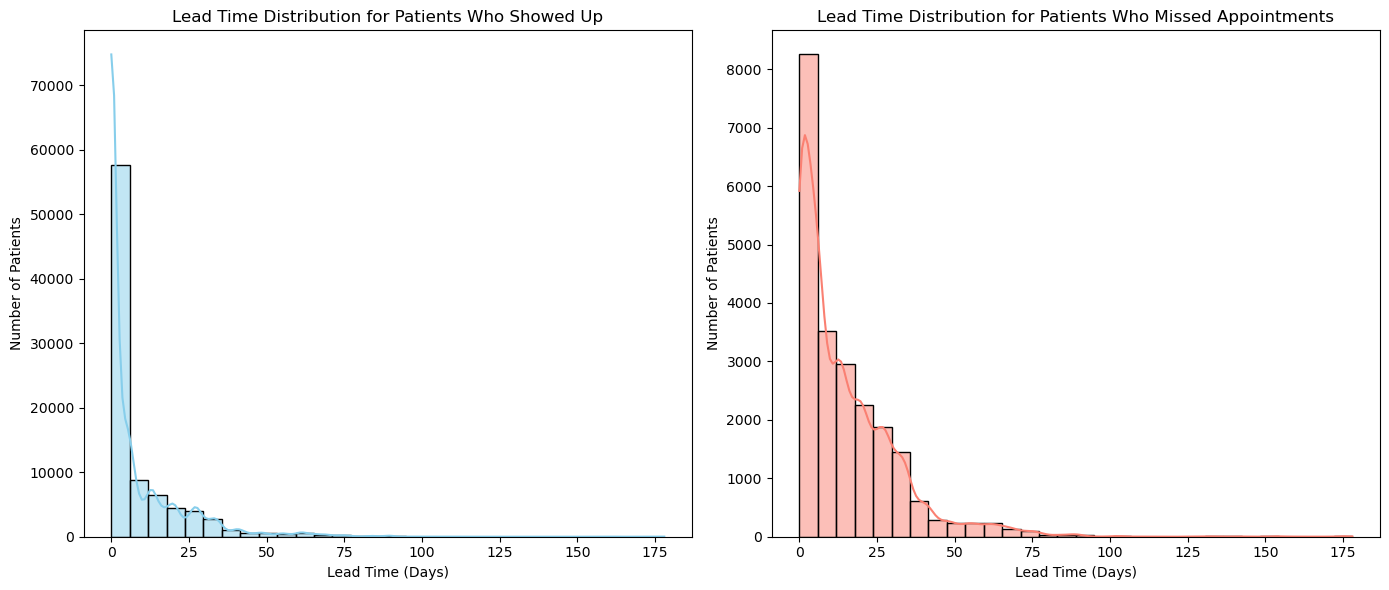

In [244]:
# Create histograms for Lead_Time for both groups
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) 
sns.histplot(lead_time_No, bins=30, kde=True, color='skyblue')
plt.title('Lead Time Distribution for Patients Who Showed Up')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Patients')
plt.savefig('Lead Time Distribution for Patients Who Showed Up.png')

plt.subplot(1, 2, 2) 
sns.histplot(lead_time_Yes, bins=30, kde=True, color='salmon')
plt.title('Lead Time Distribution for Patients Who Missed Appointments')
plt.xlabel('Lead Time (Days)')
plt.ylabel('Number of Patients')
plt.savefig('Lead Time Distribution for Patients Who Missed Appointments.png')

plt.tight_layout()
plt.show()


Since our data is skewed to the right, we'll perform a Mann Whitney U test to determine if there is a statistically significant difference in 'Lead_Time' between patients who showed up and those who did not.


*Hypotheses*:

H0: There is no significant difference in 'Lead_Time' between patients who showed up and those who did not. 

Ha: There is a significant difference in 'Lead_Time' between patients who showed up and those who did not.

Significance level (alpha) = 0.05

In [245]:
#Performing the Mann-Whitney U test
u_statistic, p_value = mannwhitneyu(lead_time_No, lead_time_Yes, alternative='two-sided')

#Print the results
print(f"Mann-Whitney U statistic: {u_statistic}")
print(f"P-value: {p_value}")

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant difference in 'Lead_Time' between patients who showed up and those who did not.")
else:
    print("\nFail to reject the null hypothesis: There is no significant difference in 'Lead_Time' between patients who showed up and those who did not.")

Mann-Whitney U statistic: 610572760.0
P-value: 0.0

Reject the null hypothesis: There is a significant difference in 'Lead_Time' between patients who showed up and those who did not.


From our analysis above, our p-value of 0.0 is smaller than alpha level of 0.05. As a result, we'll reject the null hypothesis which states that *There is a significant difference in 'Lead_Time' between patients who showed up and those who did not.*
This finding can be applied to the population at large.

Next, we'll determine if there is a statistically significant relationship between the 'Day' of appointment and 'No_Show' behavior using a chi-square test of independence.

*Hypotheses*:

H0: There is no relationship between the 'Day' of appointment and 'No_Show' behavior.

Ha: There is a significant relationship between the 'Day' of appointment and 'No_Show' behavior.

Significance level (alpha) = 0.05


In [246]:
#Creating a contingency table
contingency_table_day = pd.crosstab(no_show_analysis3['Day'], no_show_analysis3['No_Show'])
display(contingency_table_day)

No_Show,No,Yes
Day,,
Friday,14981,4037
Monday,18023,4688
Saturday,30,9
Thursday,13909,3335
Tuesday,20488,5150
Wednesday,20774,5092


In [247]:
#Running the chi2 test of independence
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table_day)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table_day.index, columns=contingency_table_day.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between Day and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between Day and No_Show.")

Chi-square statistic: 27.755658669946992
P-value: 4.062830979177125e-05
Degrees of freedom: 5


No_Show,No,Yes
Day,,
Friday,15178.641011,3839.358989
Monday,18126.097171,4584.902829
Saturday,31.126669,7.873331
Thursday,13762.776612,3481.223388
Tuesday,20462.193619,5175.806381
Wednesday,20644.164917,5221.835083



Reject the null hypothesis: There is a significant relationship between Day and No_Show.


From the chi-square test, we obtained a p-value of 4.06e-05 which is significantly smaller than our chosen significance level of 0.05. This leads us to reject the null hypothesis.

*There is a statistically significant relationship between the 'Day' of appointment and 'No_Show' behavior.*
This implies that the day of the week on which an appointment is scheduled influences the likelihood of a patient showing up.
This finding can be generalized to the larger population.

Determine relationship between 'Month' of Appointment and 'No_Show' using a chi-square test of independence.

*Hypotheses*:

H0: There is no relationship between the 'Month' of appointment and 'No_Show' behavior.

Ha: There is a significant relationship between the 'Month' of appointment and 'No_Show' behavior.

Significance level (alpha) = 0.05

In [248]:
#Cross-tabulation
contingency_table_month = pd.crosstab(no_show_analysis3['Month'], no_show_analysis3['No_Show'])
display(contingency_table_month)

No_Show,No,Yes
Month,,
April,2602,633
June,21567,4882
May,64036,16796


In [249]:
#chi2 testing
chi2, p_value, dof, expected = stats.chi2_contingency(contingency_table_month)

print(f"Chi-square statistic: {chi2}")
print(f"P-value: {p_value}")
print(f"Degrees of freedom: {dof}")
display(pd.DataFrame(expected, index=contingency_table_month.index, columns=contingency_table_month.columns))

alpha = 0.05
if p_value < alpha:
    print("\nReject the null hypothesis: There is a significant relationship between Month and No_Show.")
else:
    print("\nFail to reject the null hypothesis: There is no significant relationship between Month and No_Show.")

Chi-square statistic: 67.41006789613458
P-value: 2.3019174438039924e-15
Degrees of freedom: 2


No_Show,No,Yes
Month,,
April,2581.917324,653.082676
June,21109.468719,5339.531281
May,64513.613956,16318.386044



Reject the null hypothesis: There is a significant relationship between Month and No_Show.


chi-square test of independence confirmed a statistically significant relationship between the 'Month' of the appointment and 'No_Show' behavior. Our p-value of 2.3019e-15 was very much lower than the alpha level of 0.05 making us reject null hypothesis.
This implies that appointment month influences attendance rates.
Findings can be extrapolated to larger population.